# Problem 2 extension — Minimum sensors for a target error

Binary budget search with the existing **VND + Beam Search and Greedy**, evaluated using the actual overall sequential error including off-pair outcomes. Targets are $\epsilon\in\{0.1,0.2,0.3,0.4,0.5\}$. Each returned allocation and decision tree is explicitly verified to satisfy its target.

The result is the **smallest verified feasible budget visited by the heuristic budget search**, not a globally optimal minimum. Heuristic feasibility need not be monotone in the sensor budget.

Both modes reuse the existing 1D and 2D Extended datasets: **test** selects the same 180 instances per dimension as Problem 2; **full** uses all 2,160 per dimension. No dataset is regenerated.


In [6]:
from pathlib import Path
import sys, importlib, importlib.util
from IPython.display import display, Markdown

candidates = []
for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    candidates.extend([parent, parent/'problem-2-dual', parent/'problem-2-min-error-seq/problem-2-dual'])
HERE = next(p for p in candidates if (p/'dual_search.py').is_file())
sys.path.insert(0, str(HERE))
import dual_search
importlib.reload(dual_search)
import greedy_comparison
importlib.reload(greedy_comparison)
spec = importlib.util.spec_from_file_location('dual_reporting', HERE/'reporting.py')
dual_reporting = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dual_reporting)

RUN_MODE = 'full'  # Applies when RUN_ANALYSIS=True; saved reports use their metadata.
RUN_ANALYSIS = True
SAVED_RESULTS = HERE/'results/test/e42f02f6d2a5d551'
RESUME = True
TARGET_ERRORS = (0.1, 0.2, 0.3, 0.4, 0.5)
BEAM_WIDTH = 3
MAX_ITERATIONS = 30
TIME_LIMIT_SECONDS = None  # Optional positive per-budget heuristic time limit.
BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_SEED = 20261015


## Budget search and feasibility

The saved $N_{\min}^{\mathrm{seq}}$ is the initial upper bound. The original Problem 1 solver reconstructs its perfect allocation and covering pair-test locations. A deterministic elimination tree is built from those locations and verified with the full sequential evaluator; the saved bound must match the reconstructed minimum.

For each target, start at `low=0`, `high=N_min_seq`. Independently evaluate each method at its bisection midpoint, retaining a feasible allocation/tree and lowering `high` when the actual error is at most the target; otherwise raise `low`. Stop when `high-low <= 1`. Zero-budget guessing is checked explicitly. No sensor-budget cap of 50 is applied to this search: its upper bound is the existing sequential minimum.

A timeout retains the last verified feasible solution and is marked incomplete; it is not evidence of infeasibility. Resume retries that budget. The complete allocation and tree are saved in the results, together with a trace of evaluated budgets.


In [7]:
if RUN_ANALYSIS:
    REPORT_MODE = RUN_MODE
    REPORT_TARGET_ERRORS = TARGET_ERRORS
    solutions, failures, OUTPUT = greedy_comparison.run_comparison(
        RUN_MODE, targets=TARGET_ERRORS, beam_width=BEAM_WIDTH,
        max_iterations=MAX_ITERATIONS, time_limit=TIME_LIMIT_SECONDS,
        resume=RESUME, run=True,
    )
else:
    import json
    OUTPUT = Path(SAVED_RESULTS)
    saved_info = json.loads((OUTPUT/'run_info.json').read_text())
    REPORT_MODE = saved_info['mode']
    REPORT_TARGET_ERRORS = tuple(saved_info['targets'])
    print(f'Loading saved {REPORT_MODE} results; no searches will run.')
    if REPORT_MODE != RUN_MODE or REPORT_TARGET_ERRORS != TARGET_ERRORS:
        print('RUN_MODE and TARGET_ERRORS apply only when RUN_ANALYSIS=True.')
    solutions = json.loads((OUTPUT/'solutions.json').read_text())
    failures = json.loads((OUTPUT/'failures.json').read_text())
assert all(r['verified_feasible'] and r['actual_error'] <= r['epsilon'] for r in solutions)
assert all(sum(r['allocation']) == r['N'] <= r['N_min_seq'] for r in solutions)
print('Report mode:', REPORT_MODE)
print('Report targets:', REPORT_TARGET_ERRORS)
print('Verified solutions:', len(solutions))
print('Failed instances:', len(failures))
print('Results:', OUTPUT)

if not any(r.get('method') == 'greedy' for r in solutions):
    print('Greedy results are not saved yet. Set RUN_ANALYSIS=True to compute them; matching VND results are reused.')


Snapshot 1/4320 | 1D | gaussian | K=3, M=2
Snapshot 2/4320 | 1D | gaussian | K=3, M=2
Snapshot 3/4320 | 1D | gaussian | K=3, M=2
Snapshot 4/4320 | 1D | gaussian | K=3, M=2
Snapshot 5/4320 | 1D | gaussian | K=3, M=2
Snapshot 6/4320 | 1D | gaussian | K=3, M=2
Snapshot 7/4320 | 1D | gaussian | K=3, M=2
Snapshot 8/4320 | 1D | gaussian | K=3, M=2
Snapshot 9/4320 | 1D | gaussian | K=3, M=2
Snapshot 10/4320 | 1D | gaussian | K=3, M=2
Snapshot 11/4320 | 1D | gaussian | K=3, M=3
Snapshot 12/4320 | 1D | gaussian | K=3, M=3
Snapshot 13/4320 | 1D | gaussian | K=3, M=3
Snapshot 14/4320 | 1D | gaussian | K=3, M=3
Snapshot 15/4320 | 1D | gaussian | K=3, M=3
Snapshot 16/4320 | 1D | gaussian | K=3, M=3
Snapshot 17/4320 | 1D | gaussian | K=3, M=3
Snapshot 18/4320 | 1D | gaussian | K=3, M=3
Snapshot 19/4320 | 1D | gaussian | K=3, M=3
Snapshot 20/4320 | 1D | gaussian | K=3, M=3
Snapshot 21/4320 | 1D | gaussian | K=3, M=4
Snapshot 22/4320 | 1D | gaussian | K=3, M=4
Snapshot 23/4320 | 1D | gaussian | K=3, M

KeyboardInterrupt: 

## Required sensors versus target error

Curves use instances with completed searches for **both methods at all five targets** once both methods have results, preserving paired comparisons. The green line shows VND + Beam Search and the red dashed line shows Greedy. Both show median sensor counts; shading spans the 25th–75th percentiles (interquartile range). The band describes variability across instances, not a confidence interval. No instances are removed for having extreme sensor counts. Mean counts and their 95% bootstrap confidence intervals remain in the numerical summary, alongside the median and quartiles.

Runtime includes perfect-allocation reconstruction/verification plus target-specific budget search and actual-error evaluation. Perfect setup is shared computationally but charged once per target to represent an independent target run. Accumulated measured times are retained on resume. Both components are shown separately.


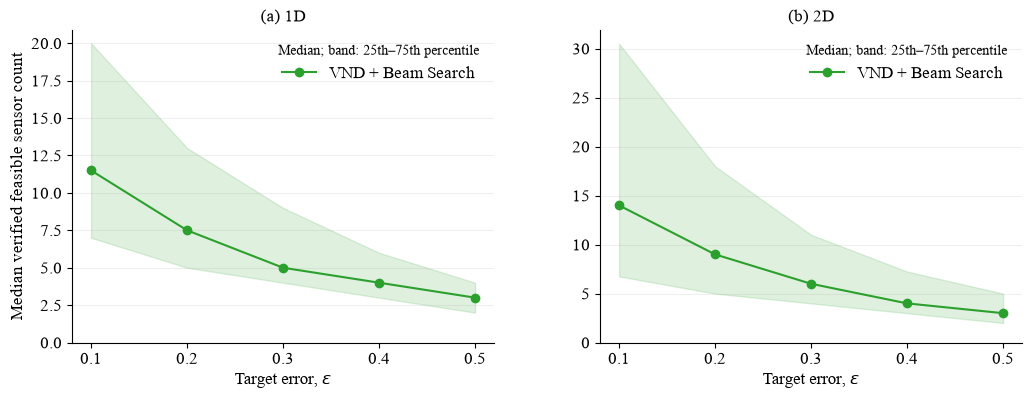

### Target-error summary

| dimension | method | epsilon | instances | median_required_sensors | q25_required_sensors | q75_required_sensors | mean_required_sensors | ci_low | ci_high | mean_runtime_seconds | mean_perfect_setup_seconds | mean_budget_search_seconds | mean_achieved_error | max_achieved_error | all_feasible |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1D | vnd_beam | 0.1 | 180 | 11.5 | 7 | 20 | 21.0167 | 15.9497 | 27.4669 | 3.75082 | 0.00891061 | 3.74191 | 0.0819362 | 0.0999236 | True |
| 1D | vnd_beam | 0.2 | 180 | 7.5 | 5 | 13 | 10.6944 | 9.28306 | 12.6669 | 3.63735 | 0.00891061 | 3.62844 | 0.170062 | 0.199894 | True |
| 1D | vnd_beam | 0.3 | 180 | 5 | 4 | 9 | 6.86111 | 6.26653 | 7.58903 | 3.6224 | 0.00891061 | 3.61349 | 0.257951 | 0.299724 | True |
| 1D | vnd_beam | 0.4 | 180 | 4 | 3 | 6 | 4.73333 | 4.39986 | 5.09444 | 3.60268 | 0.00891061 | 3.59377 | 0.350613 | 0.399951 | True |
| 1D | vnd_beam | 0.5 | 180 | 3 | 2 | 4 | 3.16111 | 2.95556 | 3.38333 | 3.55483 | 0.00891061 | 3.54592 | 0.443196 | 0.499803 | True |
| 2D | vnd_beam | 0.1 | 180 | 14 | 6.75 | 30.5 | 19076.6 | 45.0856 | 56851.9 | 4.17659 | 0.0116615 | 4.16492 | 0.0822621 | 0.1 | True |
| 2D | vnd_beam | 0.2 | 180 | 9 | 5 | 18 | 98.0278 | 14.4271 | 259.122 | 4.02637 | 0.0116615 | 4.01471 | 0.169995 | 0.199993 | True |
| 2D | vnd_beam | 0.3 | 180 | 6 | 4 | 11 | 44.8167 | 8.32764 | 115.664 | 3.94328 | 0.0116615 | 3.93162 | 0.259643 | 0.299995 | True |
| 2D | vnd_beam | 0.4 | 180 | 4 | 3 | 7.25 | 16.45 | 5.42181 | 37.7507 | 3.90589 | 0.0116615 | 3.89423 | 0.349698 | 0.399992 | True |
| 2D | vnd_beam | 0.5 | 180 | 3 | 2 | 5 | 4.48333 | 3.62778 | 5.81111 | 3.91028 | 0.0116615 | 3.89862 | 0.44617 | 0.499992 | True |

### Coverage

| dimension | selected_instances | complete_paired_instances | failed_instances | interrupted_targets |
| --- | --- | --- | --- | --- |
| 1D | 180 | 180 | 0 | 0 |
| 2D | 180 | 180 | 0 | 0 |

In [ ]:
import matplotlib.pyplot as plt

figure, summary, coverage = dual_reporting.report(
    solutions, failures, OUTPUT, REPORT_TARGET_ERRORS,
    resamples=BOOTSTRAP_RESAMPLES, seed=BOOTSTRAP_SEED,
)
display(figure)
plt.close(figure)

def show_table(rows):
    if not rows:
        print('No rows available')
        return
    columns = list(rows[0])
    lines = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---']*len(columns)) + ' |']
    for row in rows:
        lines.append('| ' + ' | '.join(f'{row[k]:.6g}' if isinstance(row[k],float) else str(row[k]) for k in columns) + ' |')
    display(Markdown('\n'.join(lines)))

display(Markdown('### Target-error summary'))
show_table(summary)
display(Markdown('### Coverage'))
show_table(coverage)
if failures:
    display(Markdown('### Failed instances (first 20; all retained in failures.json)'))
    show_table(failures[:20])


## Saved results

- `solutions.json`: verified sensor counts, allocations, decision trees, actual errors, runtimes and budget-search traces.
- `verified_solutions.csv`: scalar results, including verified fallback solutions from interrupted searches.
- `summary.csv` and `coverage.csv`: paired summary statistics and exclusions.
- `required_sensors_vs_target.pdf` and `.png`: vector PDF and 600-dpi PNG exports.
- `failures.json` and `run_info.json`: failures, settings and source fingerprints.

Set `RUN_ANALYSIS=False` and select `SAVED_RESULTS` to rebuild reports directly from saved JSON files without running any searches or error evaluations. Existing Problem 1/2 algorithms and datasets are not modified by this extension.
